# Домашнее задание
### школа аналитиков HH.RU · введение в статистику
#### Иващенко Юлия

In [19]:
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from scipy.stats import norm, ttest_ind, mannwhitneyu

rng = np.random.default_rng(7)
alpha = 0.05

## Задача 1

Пусть μ — среднее время на карточке вакансии в генеральной совокупности, тогда

- H0: μ = 120 секунд
- H1: μ != 120 секунд

Разброс одного наблюдения известен, поэтому используем z-критерий



In [20]:
n = 100
x_mean = 124
mu_0 = 120
sigma = 25

se = sigma / np.sqrt(n)
z = (x_mean - mu_0) / se

p_value = 2 * norm.sf(abs(z))

print(f"Стандартная ошибка: {se:.3f}")
print(f"z-статистика: {z:.3f}")
print(f"p-value: {p_value:.4f}")

if p_value < alpha:
    print("H0 отвергается")
else:
    print("Нет оснований отвергать H0")

Стандартная ошибка: 2.500
z-статистика: 1.600
p-value: 0.1096
Нет оснований отвергать H0


### Вывод

Выборочное среднее оказалось выше 120 секунд на 1,6 стандартной ошибки. Полученное p-value около 0,1096 что больше 0,05, поэтому оснований отвергать H0 нет. Разница в 4 секунды статистически незначима на выбранном уровне, хотя это не доказывает, что среднее точно равно 120 секундам

## Задача 2

Будем считать разницу как среднее второй группы минус среднее первой, тогда
Δ = 55 − 50 = 5

Генеральные стандартные отклонения неизвестны, поэтому используем доверительный интервал Уэлча.

In [21]:
n1, n2 = 40, 40
mean1, mean2 = 50, 55
s1, s2 = 10, 10

diff = mean2 - mean1

v1 = s1**2 / n1
v2 = s2**2 / n2

se = np.sqrt(v1 + v2)

df = (v1 + v2)**2 / (
    v1**2 / (n1 - 1) + v2**2 / (n2 - 1)
)

t_crit = stats.t.ppf(1 - alpha / 2, df)

ci_low = diff - t_crit * se
ci_high = diff + t_crit * se

print(f"Разница средних: {diff:.3f}")
print(f"Стандартная ошибка разницы: {se:.3f}")
print(f"Число степеней свободы: {df:.1f}")
print(f"95% доверительный интервал: [{ci_low:.3f}; {ci_high:.3f}]")
print("Ноль входит в интервал:", ci_low <= 0 <= ci_high)

Разница средних: 5.000
Стандартная ошибка разницы: 2.236
Число степеней свободы: 78.0
95% доверительный интервал: [0.548; 9.452]
Ноль входит в интервал: False


Разница средних равна 5, а 95% доверительный интервал составляет примерно [0,55; 9,45]. Ноль в интервал не входит, поэтому гипотезу о равенстве средних отвергаем на уровне 5%

Наименьшее значение разницы, входящее в этот интервал, составляет около 0,55. Это нижняя граница интервала, а не гарантия того, что истинный эффект обязательно больше неё

### Задача 3

Пусть p1 и p2 — вероятности отклика в первой и второй группах тогда,

H0: p1 = p2

H1: p1 != p2

In [22]:
x1, n1 = 90, 1000
x2, n2 = 120, 1000

p1 = x1 / n1
p2 = x2 / n2

p_common = (x1 + x2) / (n1 + n2)
diff_pp = (p2 - p1) * 100

se = np.sqrt(
    p_common * (1 - p_common) * (1 / n1 + 1 / n2)
)

z = (p2 - p1) / se
p_value = 2 * stats.norm.sf(abs(z))

print(f"Конверсия первой группы: {p1:.2%}")
print(f"Конверсия второй группы: {p2:.2%}")
print(f"Разница конверсий: {diff_pp:.2f} п.п.")
print(f"z-статистика: {z:.3f}")
print(f"p-value: {p_value:.4f}")

Конверсия первой группы: 9.00%
Конверсия второй группы: 12.00%
Разница конверсий: 3.00 п.п.
z-статистика: 2.188
p-value: 0.0287


Конверсия второй группы выше на 3 процентных пункта: 12% против 9%. Статистика критерия равна примерно 2,188, p-value около 0,0287. Поскольку p-value меньше 0,05, отвергаем H0. Разница конверсий статистически значима

### Задача 4

Проведём 2000 экспериментов. В каждом заново наберём две независимые группы по 200 наблюдений из N(0, 1)

Обе группы имеют одинаковое распределение, поэтому гипотеза о равенстве средних верна. В каждом эксперименте посчитаем t Уэлча и p-value, затем построим распределение p-value.

Доля отклонений H0: 5.70%


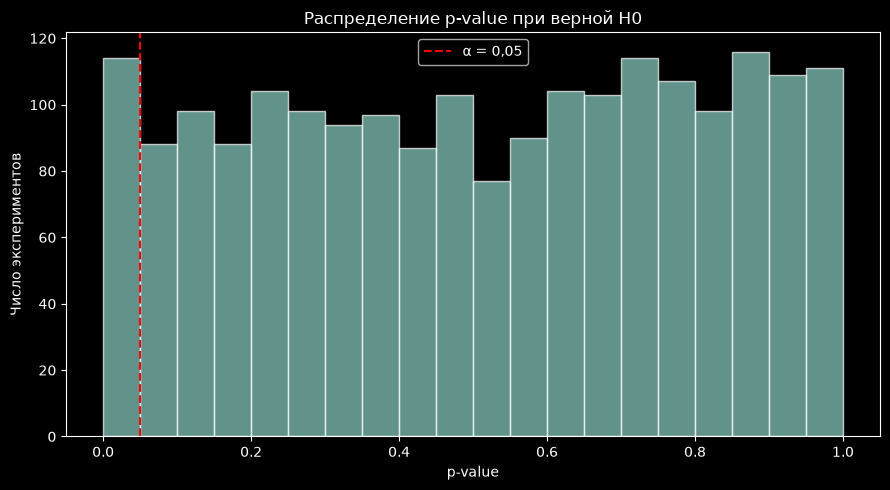

In [23]:
rng = np.random.default_rng(7)
n_repeats = 2000

t_values = []
p_values = []

for _ in range(n_repeats):
    group1 = rng.normal(loc=0, scale=1, size=200)
    group2 = rng.normal(loc=0, scale=1, size=200)

    result = stats.ttest_ind(
        group2,
        group1,
        equal_var=False,
        alternative="two-sided"
    )

    t_values.append(result.statistic)
    p_values.append(result.pvalue)

p_values = np.array(p_values)

print(f"Доля отклонений H0: {np.mean(p_values < alpha):.2%}")

plt.figure(figsize=(9, 5))
plt.hist(
    p_values,
    bins=np.linspace(0, 1, 21),
    alpha=0.7,
    edgecolor="white"
)
plt.axvline(
    alpha,
    color="red",
    linestyle="--",
    label="α = 0,05"
)
plt.title("Распределение p-value при верной H0")
plt.xlabel("p-value")
plt.ylabel("Число экспериментов")
plt.legend()
plt.tight_layout()
plt.show()

Гистограмма p-value примерно равномерна на отрезке от 0 до 1. При верной H0 и корректно работающем непрерывном критерии маленькие p-value встречаются с соответствующей частотой: например, значения ниже 0,05 возникают примерно в 5% экспериментов.

В симуляции H0 отверглась в 5,7% случаев. Это ошибки первого рода, поскольку средние на самом деле равны. Небольшое отличие от 5% связано со случайностью моделирования.

### Задача 5

Проведём 1000 экспериментов. В каждом наберём первую группу из N(0, 1), вторую из N(1, 1), по 60 наблюдений. Затем заменим два значения второй группы на −50.

Посчитаем разницу средних между второй и первой, t Уэлча, U Манна–Уитни для первой группы и p-value обоих критериев.

Для Уэлча H0 означает равенство средних. Для Манна–Уитни используем H0 о совпадении распределений. Оба критерия применим с двусторонней альтернативой.

t считаем для второй группы относительно первой, поэтому его знак совпадает со знаком разницы средних.
U по условию считаем для первой группы

In [24]:
rng = np.random.default_rng(7)
n_repeats = 1000

mean_diffs = []
t_values = []
u_values = []
p_values_t = []
p_values_u = []

for _ in range(n_repeats):
    group1 = rng.normal(loc=0, scale=1, size=60)
    group2 = rng.normal(loc=1, scale=1, size=60)

    group2[:2] = -50

    t_result = stats.ttest_ind(
        group2,
        group1,
        equal_var=False,
        alternative="two-sided"
    )

    u_result = stats.mannwhitneyu(
        group1,
        group2,
        alternative="two-sided"
    )

    mean_diffs.append(group2.mean() - group1.mean())
    t_values.append(t_result.statistic)
    u_values.append(u_result.statistic)
    p_values_t.append(t_result.pvalue)
    p_values_u.append(u_result.pvalue)

mean_diffs = np.array(mean_diffs)
p_values_t = np.array(p_values_t)
p_values_u = np.array(p_values_u)

print(f"Средняя разница средних: {mean_diffs.mean():.3f}")
print(f"Средняя t-статистика: {np.mean(t_values):.3f}")
print(f"Средняя U-статистика: {np.mean(u_values):.3f}")

print(
    "Доля отклонений H₀ по Уэлчу: "
    f"{np.mean(p_values_t < alpha):.2%}"
)
print(
    "Доля отклонений H₀ по Манна–Уитни: "
    f"{np.mean(p_values_u < alpha):.2%}"
)
print(
    "Доля экспериментов с разными решениями: "
    f"{np.mean((p_values_t < alpha) != (p_values_u < alpha)):.2%}"
)

Средняя разница средних: -0.686
Средняя t-статистика: -0.569
Средняя U-статистика: 941.353
Доля отклонений H₀ по Уэлчу: 0.00%
Доля отклонений H₀ по Манна–Уитни: 100.00%
Доля экспериментов с разными решениями: 100.00%


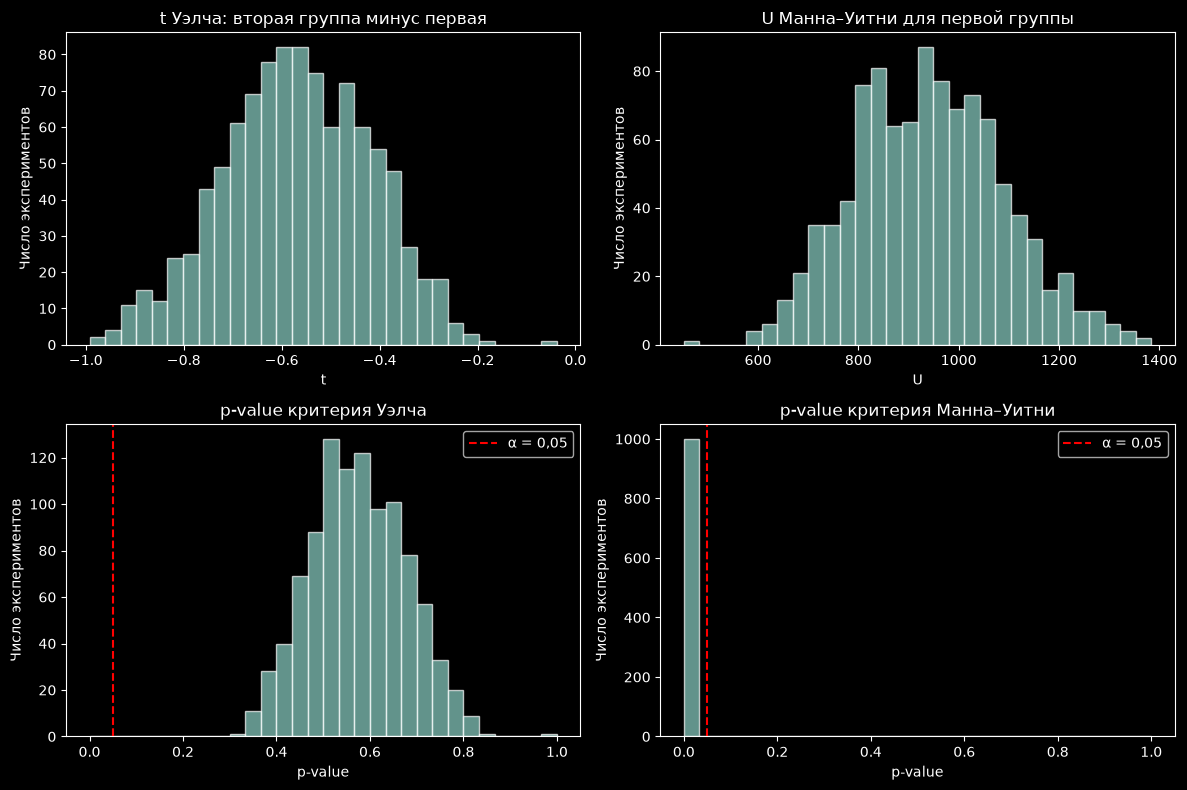

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(
    t_values, bins=30, alpha=0.7, edgecolor="white"
)
axes[0, 0].set_title("t Уэлча: вторая группа минус первая")
axes[0, 0].set_xlabel("t")

axes[0, 1].hist(
    u_values, bins=30, alpha=0.7, edgecolor="white"
)
axes[0, 1].set_title("U Манна–Уитни для первой группы")
axes[0, 1].set_xlabel("U")

bins = np.linspace(0, 1, 31)

axes[1, 0].hist(
    p_values_t, bins=bins, alpha=0.7, edgecolor="white"
)
axes[1, 0].set_title("p-value критерия Уэлча")

axes[1, 1].hist(
    p_values_u, bins=bins, alpha=0.7, edgecolor="white"
)
axes[1, 1].set_title("p-value критерия Манна–Уитни")

for ax in axes[1]:
    ax.axvline(
        alpha,
        color="red",
        linestyle="--",
        label="α = 0,05"
    )
    ax.set_xlabel("p-value")
    ax.legend()

for ax in axes.flat:
    ax.set_ylabel("Число экспериментов")

plt.tight_layout()
plt.show()

Средняя разница средних получилась около −0,686. Два значения −50 настолько сильно снизили среднее второй группы, что разница поменяла знак. Одновременно они сильно увеличили её дисперсию.

Распределение t сосредоточено около −0,57, а U — около 941. p-value Уэлча находятся преимущественно около 0,5–0,6, а p-value Манна–Уитни — около нуля.

В этих 1000 экспериментах Уэлч ни разу не отверг H0, а Манна–Уитни отверг свою H0 во всех случаях. Решения разошлись во всех экспериментах

Уэлч сравнивает средние и учитывает разброс, который сильно вырос из-за выбросов. Манна–Уитни использует ранги: для него важно положение наблюдений относительно друг друга, а не то, насколько далеко находятся значения −50. Большинство наблюдений второй группы по-прежнему больше наблюдений первой

### Задача 6

Один раз наберём первую группу из N(10, 2), размером 80 наблюдений, и вторую из N(10,8, 2,6), размером 75 наблюдений

Будем оценивать разницу средних «вторая минус первая».

H0: μ2 − μ1 = 0

H1: μ2 − μ1 != 0

Посчитаем разницу средних, 95% доверительный интервал Уэлча и p-value

In [26]:
rng = np.random.default_rng(7)

group1_6 = rng.normal(loc=10, scale=2, size=80)
group2_6 = rng.normal(loc=10.8, scale=2.6, size=75)

diff_6 = group2_6.mean() - group1_6.mean()

result_6 = stats.ttest_ind(
    group2_6,
    group1_6,
    equal_var=False,
    alternative="two-sided"
)

ci_6 = result_6.confidence_interval(confidence_level=0.95)

print(f"Среднее первой группы: {group1_6.mean():.3f}")
print(f"Среднее второй группы: {group2_6.mean():.3f}")
print(f"Разница средних: {diff_6:.3f}")
print(f"t-статистика: {result_6.statistic:.3f}")
print(f"p-value: {result_6.pvalue:.4f}")
print(
    "95% доверительный интервал: "
    f"[{ci_6.low:.3f}; {ci_6.high:.3f}]"
)
print("Ноль входит в интервал:", ci_6.low <= 0 <= ci_6.high)

Среднее первой группы: 9.647
Среднее второй группы: 10.404
Разница средних: 0.757
t-статистика: 2.308
p-value: 0.0225
95% доверительный интервал: [0.109; 1.404]
Ноль входит в интервал: False


Средние первой и второй групп получились примерно 9,647 и 10,404. Разница составляет 0,757, а 95% доверительный интервал — примерно [0,109; 1,404].

Ноль в интервал не входит, p-value около 0,0225, что меньше 0,05. Поэтому отвергаем H0 о равенстве средних: различие статистически значимо.

Наименьшее значение разницы, входящее в полученный интервал, составляет примерно 0,109

### Задача 7

Возьмём те же группы, что в задании 6. Будем отдельно выбирать наблюдения из каждой группы с возвращением, сохраняя исходные размеры выборок.

Повторим это 2000 раз и каждый раз посчитаем разницу средних между второй и первой группами.

Границами 95% доверительного интервала будут 2,5-й и 97,5-й перцентили полученных разниц. Также посчитаем долю повторов, в которых разница оказалась не больше нуля

95% интервал бутстрапа: [0.101; 1.389]
95% интервал Уэлча: [0.109; 1.404]
Доля разниц не больше нуля: 1.10%


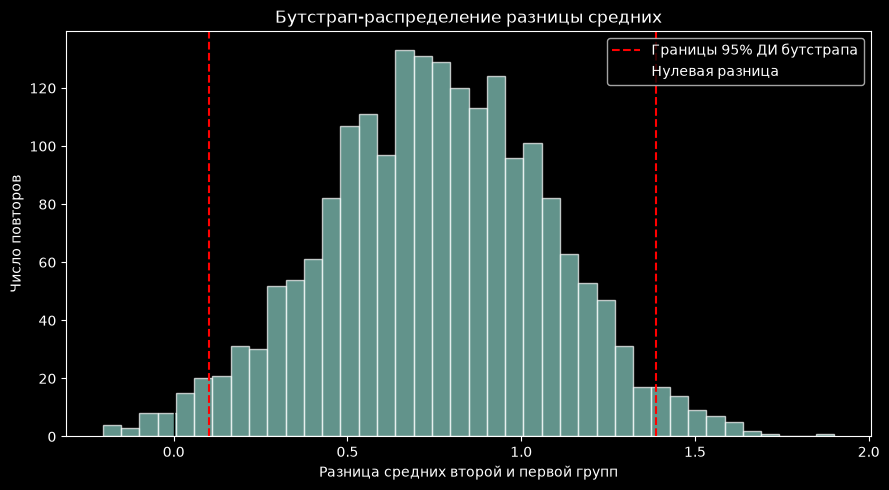

In [27]:
rng = np.random.default_rng(7)

bootstrap_diffs = []

for _ in range(2000):
    sample1 = rng.choice(
        group1_6,
        size=len(group1_6),
        replace=True
    )
    sample2 = rng.choice(
        group2_6,
        size=len(group2_6),
        replace=True
    )

    bootstrap_diffs.append(sample2.mean() - sample1.mean())

bootstrap_diffs = np.array(bootstrap_diffs)

ci_boot = np.percentile(bootstrap_diffs, [2.5, 97.5])
share_nonpositive = np.mean(bootstrap_diffs <= 0)

print(
    "95% интервал бутстрапа: "
    f"[{ci_boot[0]:.3f}; {ci_boot[1]:.3f}]"
)
print(
    "95% интервал Уэлча: "
    f"[{ci_6.low:.3f}; {ci_6.high:.3f}]"
)
print(f"Доля разниц не больше нуля: {share_nonpositive:.2%}")

plt.figure(figsize=(9, 5))
plt.hist(
    bootstrap_diffs,
    bins=40,
    alpha=0.7,
    edgecolor="white"
)
plt.axvline(
    ci_boot[0],
    color="red",
    linestyle="--",
    label="Границы 95% ДИ бутстрапа"
)
plt.axvline(
    ci_boot[1],
    color="red",
    linestyle="--"
)
plt.axvline(
    0,
    color="black",
    linewidth=1,
    label="Нулевая разница"
)
plt.title("Бутстрап-распределение разницы средних")
plt.xlabel("Разница средних второй и первой групп")
plt.ylabel("Число повторов")
plt.legend()
plt.tight_layout()
plt.show()

Бутстрап-распределение имеет форму, близкую к колоколу, и сосредоточено около наблюдаемой разницы средних 0,757.

95% интервал бутстрапа получился примерно [0,101; 1,389], а интервал Уэлча — [0,109; 1,404]. Границы близки, и оба интервала не содержат ноль.

В 1,1% бутстрап-повторов разница оказалась не больше нуля. Эту долю нельзя напрямую назвать p-value. Здесь мы повторно выбираем наблюдения из исходных групп и получаем распределение вокруг наблюдаемого эффекта. Для p-value нужно оценивать, насколько экстремален наблюдаемый результат при верной H0. Кроме того, посчитанная доля относится только к одному хвосту, а проверка в задании двусторонняя